# step0_eda
**Owner:** P2

**Purpose:** Re-run every analysis in the interim report on the full MIND-large data, then report only what is different or interesting (Section 6 lists the differences). Also adds the cold-threshold sensitivity check and the Fit / Tune / Test split view.

**Inputs:** raw MIND-large files `MINDlarge_train` and `MINDlarge_dev` (the project does not use `MINDlarge_test`; if that folder is present it is only used for a few extra coverage numbers). The data comes from the shared Drive (Colab) or from a folder on your own computer (`LOCAL_DATA` in the setup cell). This notebook reads the raw files, not `data/processed/`, because the processed training data is negative-sampled and would distort slate and click statistics.

**Outputs:** figures (`.png`) and tables (`.csv`) in `step0_eda_outputs/` next to the notebook (copy it to `outputs/step0_eda/` on the shared Drive afterwards)

**Split names.** The team README and MIND use different names for the same data. This notebook uses MIND's names (Train, Dev, Test) in tables and adds the README names in Section 2.

| README name | MIND folder / notebook name | Dates | Labels |
|---|---|---|---|
| Fit | Train | 9-13 Nov | yes |
| Tune | Train | 14 Nov | yes |
| Test | **Dev** | 15 Nov | yes |
| (not used) | Test | 16-22 Nov | no |

> Runtime: Colab (standard runtime) or a local Jupyter / VS Code kernel with `pandas`, `pyarrow` and `matplotlib` installed (`pip install pandas pyarrow matplotlib`). The one-off pass over the training file takes several minutes and is cached in the output folder. Run all cells top to bottom; keep outputs saved.

In [2]:
# --- Setup: run this first ---
# Colab: leave LOCAL_DATA as None (uses the shared BT4222_Project folder on your Drive, see README).
# Own computer: set it to the folder that holds MINDlarge_train and MINDlarge_dev, e.g. r"C:\Users\me\MIND"
LOCAL_DATA = None
OUT = "step0_eda_outputs"      # results are saved here, next to the notebook (on Colab this disk is temporary: download it afterwards)

import os, sys, subprocess
try:
    from google.colab import drive
    if not LOCAL_DATA:
        drive.mount("/content/drive")
except ImportError:
    pass

# the group repo (config.py, utils/): use the one this notebook sits in, otherwise download it next to the notebook
if not os.path.isfile("config.py"):
    if not os.path.isdir("BT4222-Project-Group-4--MIND"):
        subprocess.run(["git", "clone", "-q", "https://github.com/Fdiannz/BT4222-Project-Group-4--MIND"], check=True)
    sys.path.insert(0, os.path.abspath("BT4222-Project-Group-4--MIND"))
sys.path.insert(0, os.path.abspath("."))

import re, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import config
from utils.data_utils import load_news, load_behaviors, explode_impressions

if LOCAL_DATA:
    TRAIN_DIR, DEV_DIR, TEST_DIR = (os.path.join(LOCAL_DATA, d) for d in ("MINDlarge_train", "MINDlarge_dev", "MINDlarge_test"))
else:
    TRAIN_DIR, DEV_DIR, TEST_DIR = config.TRAIN_DIR, config.DEV_DIR, config.TEST_DIR
for d in (TRAIN_DIR, DEV_DIR):
    assert os.path.isfile(os.path.join(d, "behaviors.tsv")), f"Cannot find {d}/behaviors.tsv - see the first lines of this cell"
HAS_TEST = os.path.isfile(os.path.join(TEST_DIR, "behaviors.tsv"))      # optional; the project does not use it
os.makedirs(OUT, exist_ok=True)

SAMPLE_N = 300_000      # random whole-session sample, as in the interim report (Section 2.3)
CHUNK = 200_000         # sessions per chunk in the one-off pass over the training file
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Data   :", TRAIN_DIR, "...\nOutputs:", os.path.abspath(OUT))


Mounted at /content/drive
Data   : /content/drive/MyDrive/BT4222_Project/data/raw/MINDlarge_train ...
Outputs: /content/step0_eda_outputs


## 0. Helpers
`session_table` reads slate length, clicks and history length straight from the raw strings, so whole-split statistics need no expansion to 83M rows.
`R` collects the key numbers; the last section compares them with the interim report.

In [3]:
R = {}   # key numbers, compared with the interim report at the end


def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{OUT}/{name}.png", dpi=150)
    plt.show()


def save(df, name):
    df.to_csv(f"{OUT}/{name}.csv")
    return df


def session_table(b):
    """One row per session: slate length, clicks, history length (read from the raw strings)."""
    s = b[["impression_id", "user_id", "time"]].copy()
    s["slate_len"] = b["impressions"].str.count(" ") + 1
    s["clicks"] = b["impressions"].str.count("-1")            # labelled splits only (test has no labels)
    s["hist_len"] = np.where(b["history"] == "", 0, b["history"].str.count(" ") + 1)
    return s


def describe_num(x, name):
    x = pd.Series(x)
    miss = int(x.isna().sum())
    x = x.dropna()
    return {"feature": name, "n": len(x), "missing": miss, "min": x.min(), "median": x.median(),
            "mean": round(x.mean(), 4), "std": round(x.std(), 4), "max": x.max()}

## 1. Load the three splits
Behaviors are kept as raw strings (train and dev) so impressions can be expanded later; the optional test split (if the folder is present) only needs its session table.

In [4]:
beh, news, sess = {}, {}, {}
splits_on_disk = {"Train": TRAIN_DIR, "Dev": DEV_DIR}
if HAS_TEST:
    splits_on_disk["Test"] = TEST_DIR      # optional: only adds the official test split to the coverage table
for name, d in splits_on_disk.items():
    t0 = time.time()
    b = load_behaviors(f"{d}/behaviors.tsv")
    news[name] = load_news(f"{d}/news.tsv")
    sess[name] = session_table(b)
    if name != "Test":
        beh[name] = b
    print(f"{name}: {len(b):,} sessions, {len(news[name]):,} news rows ({time.time() - t0:.0f}s)")
    del b

Train: 2,232,748 sessions, 101,527 news rows (69s)
Dev: 376,471 sessions, 72,023 news rows (16s)
Test: 2,370,727 sessions, 120,961 news rows (78s)


## 2. Dataset coverage and sampling (report Sections 2.1 and 2.3)
Counts come from the full files. Impression logs run from 9 to 22 November; the six-week window in the documentation (12 Oct to 22 Nov) is the click-history window.

In [5]:
rows = []
for name, s in sess.items():
    lab = name != "Test"
    n = news[name]
    rows.append({
        "split": name, "sessions": len(s), "unique_users": s["user_id"].nunique(),
        "earliest": s["time"].min(), "latest": s["time"].max(),
        "news_rows": len(n), "unique_articles": n["news_id"].nunique(),
        "candidate_displays": int(s["slate_len"].sum()),
        "clicked": int(s["clicks"].sum()) if lab else np.nan,
        "non_clicked": int(s["slate_len"].sum() - s["clicks"].sum()) if lab else np.nan,
        "ctr_%": round(100 * s["clicks"].sum() / s["slate_len"].sum(), 3) if lab else np.nan,
        "sessions_without_history": int((s["hist_len"] == 0).sum()),
        "without_history_%": round(100 * (s["hist_len"] == 0).mean(), 2)})
coverage = save(pd.DataFrame(rows, dtype=object).set_index("split"), "coverage_by_split")
display(coverage.T)

allsess = pd.concat(sess.values())
overall = pd.Series({
    "sessions": len(allsess),
    "unique_users": allsess["user_id"].nunique(),
    "unique_articles": pd.concat([n["news_id"] for n in news.values()]).nunique(),
    "candidate_displays": int(allsess["slate_len"].sum())})
display(save(overall.to_frame("all splits"), "coverage_overall"))
R["coverage"], R["overall"] = coverage, overall

split,Train,Dev,Test
sessions,2232748,376471,2370727
unique_users,711222,255990,702005
earliest,2019-11-09 00:00:00,2019-11-15 00:00:00,2019-11-16 00:00:05
latest,2019-11-14 23:59:59,2019-11-15 23:59:43,2019-11-22 23:59:58
news_rows,101527,72023,120961
unique_articles,101527,72023,120961
candidate_displays,83507374,14085557,93115001
clicked,3383656,574845,NaN
non_clicked,80123718,13510712,NaN
ctr_%,4.052,4.081,NaN


,all splits
sessions,4979946
unique_users,876956
unique_articles,130379
candidate_displays,190707932


### Team split names (README: Fit / Tune / Test)
Same data, re-cut by the README's names. Fit and Tune are the first and last parts of MIND's train folder; README "Test" is MIND's dev folder.

In [6]:
tune_day = pd.Timestamp(str(config.TUNE_DATE)).normalize()
parts = {"Fit (train, before tune day)": sess["Train"][sess["Train"]["time"] < tune_day],
         "Tune (train, tune day)": sess["Train"][sess["Train"]["time"] >= tune_day],
         "Test (MIND dev)": sess["Dev"]}
rows = []
for name, s in parts.items():
    rows.append({"split": name, "from": s["time"].min(), "to": s["time"].max(), "sessions": len(s),
                 "unique_users": s["user_id"].nunique(), "candidate_displays": int(s["slate_len"].sum()),
                 "clicked": int(s["clicks"].sum()), "ctr_%": round(100 * s["clicks"].sum() / s["slate_len"].sum(), 3),
                 "median_slate_len": s["slate_len"].median(), "without_history_%": round(100 * (s["hist_len"] == 0).mean(), 2)})
fit_tune_test = save(pd.DataFrame(rows, dtype=object).set_index("split"), "fit_tune_test_split")
display(fit_tune_test.T)

split,"Fit (train, before tune day)","Tune (train, tune day)",Test (MIND dev)
from,2019-11-09 00:00:00,2019-11-14 00:00:00,2019-11-15 00:00:00
to,2019-11-13 23:59:57,2019-11-14 23:59:59,2019-11-15 23:59:43
sessions,1801231,431517,376471
unique_users,654870,286814,255990
candidate_displays,66107268,17400106,14085557
clicked,2712612,671044,574845
ctr_%,4.103,3.857,4.081
median_slate_len,24.0,26.0,23.0
without_history_%,1.92,2.64,2.99


In [7]:
tr = sess["Train"]
samp = tr.sample(n=min(SAMPLE_N, len(tr)), random_state=config.SEED)


def block(s):
    return {"sessions": len(s), "unique_users": s["user_id"].nunique(),
            "candidate_displays": int(s["slate_len"].sum()), "clicked": int(s["clicks"].sum()),
            "non_clicked": int((s["slate_len"] - s["clicks"]).sum()),
            "ctr_%": round(100 * s["clicks"].sum() / s["slate_len"].sum(), 3),
            "mean_slate": round(s["slate_len"].mean(), 2), "median_slate": s["slate_len"].median(),
            "sessions_without_history": int((s["hist_len"] == 0).sum()),
            "without_history_%": round(100 * (s["hist_len"] == 0).mean(), 2)}


sample_vs_full = save(pd.DataFrame({"Full training data": block(tr),
                                    f"{len(samp):,}-session sample": block(samp)}, dtype=object), "sample_vs_full")
display(sample_vs_full)

,Full training data,"300,000-session sample"
sessions,2232748.0,300000.0
unique_users,711222.0,228407.0
candidate_displays,83507374.0,11207268.0
clicked,3383656.0,453663.0
non_clicked,80123718.0,10753605.0
ctr_%,4.052,4.048
mean_slate,37.4,37.36
median_slate,25.0,25.0
sessions_without_history,46065.0,6204.0
without_history_%,2.06,2.07


## 3. Impressions, exposure and interaction dynamics (report Section 3)
### 3.1 Slate length and position
Slate length uses the 300k-session sample (as in the report). Position CTR needs the candidate order, so the sample is expanded to candidate rows.

,slate length
min,2.00
max,299.00
mean,37.36
median,25.00
std,38.62
Q1,10.00
Q3,51.00
share_<=10_%,27.09
p99,165.00


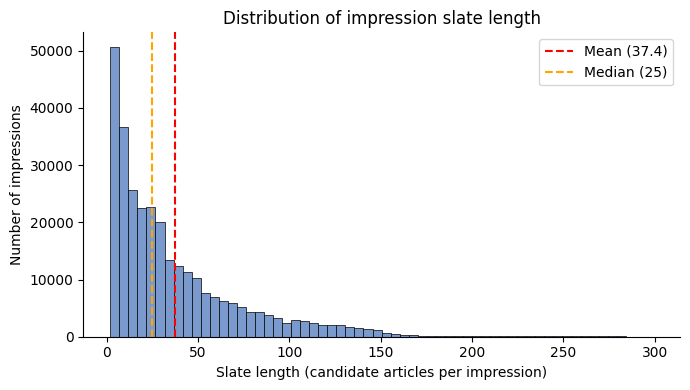

In [8]:
L = samp["slate_len"]
slate_stats = pd.Series({"min": L.min(), "max": L.max(), "mean": L.mean(), "median": L.median(), "std": L.std(),
                         "Q1": L.quantile(.25), "Q3": L.quantile(.75), "share_<=10_%": 100 * (L <= 10).mean(),
                         "p99": L.quantile(.99)}).round(2)
display(save(slate_stats.to_frame("slate length"), "slate_length_stats"))
R["slate_stats"] = slate_stats

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(L, bins=60, color="#7a99cc", edgecolor="black", linewidth=.5)
ax.axvline(L.mean(), color="red", ls="--", label=f"Mean ({L.mean():.1f})")
ax.axvline(L.median(), color="orange", ls="--", label=f"Median ({L.median():.0f})")
ax.set(title="Distribution of impression slate length", xlabel="Slate length (candidate articles per impression)",
       ylabel="Number of impressions")
ax.legend()
savefig("fig_slate_length")

pos,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
all_slates_%,10.87,10.74,8.01,7.41,6.57,6.10,5.98,5.38,5.30,5.06,...,3.74,3.77,3.68,3.55,3.53,3.47,3.5,3.35,3.31,3.17
slates_40-49_%,3.83,3.99,3.89,3.78,3.86,3.63,3.93,3.75,3.89,3.94,...,3.67,3.79,3.97,3.91,3.82,3.68,3.9,4.08,3.82,3.73


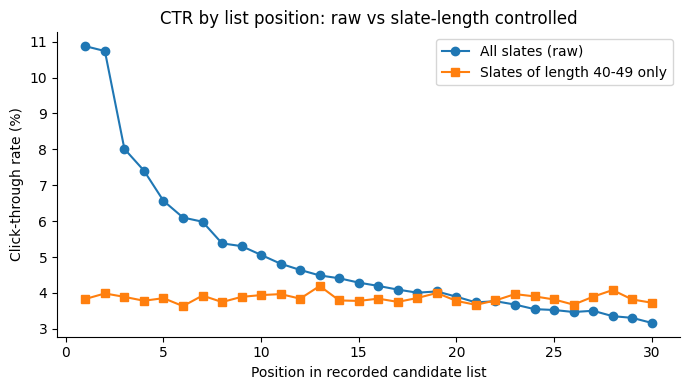

In [9]:
cand = explode_impressions(beh["Train"].loc[samp.index], keep_cols=("impression_id", "time"))
cand["pos"] = cand.groupby("impression_id", sort=False).cumcount() + 1
cand["slate_len"] = cand.groupby("impression_id", sort=False)["pos"].transform("max")

raw_pos = cand[cand["pos"] <= 30].groupby("pos")["label"].mean() * 100
ctrl_pos = cand[(cand["pos"] <= 30) & cand["slate_len"].between(40, 49)].groupby("pos")["label"].mean() * 100
pos_ctr = save(pd.DataFrame({"all_slates_%": raw_pos, "slates_40-49_%": ctrl_pos}).round(2), "ctr_by_position")
display(pos_ctr.T)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(raw_pos.index, raw_pos, "o-", label="All slates (raw)")
ax.plot(ctrl_pos.index, ctrl_pos, "s-", label="Slates of length 40-49 only")
ax.set(title="CTR by list position: raw vs slate-length controlled", xlabel="Position in recorded candidate list",
       ylabel="Click-through rate (%)")
ax.legend()
savefig("fig_ctr_by_position")

,sessions,displays,clicks,ctr_%
slate_len,,,,
0-9,544537,2574939,570113,22.14
10-19,401350,5584296,484447,8.68
20-29,323065,7868501,445142,5.66
30-39,216158,7375167,332609,4.51
40-49,164288,7302381,278620,3.82
50-59,114893,6227718,207615,3.33
60-69,96640,6222342,187397,3.01
70-79,75162,5583208,151537,2.71
80-89,61224,5171407,132389,2.56


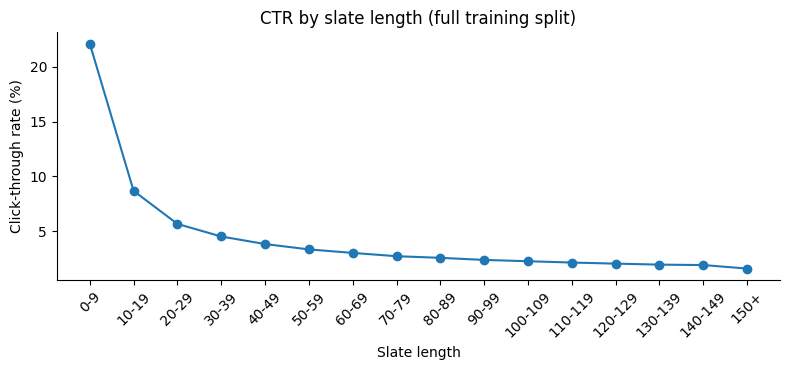

In [10]:
bins = list(range(0, 160, 10)) + [np.inf]
names = [f"{a}-{a + 9}" for a in range(0, 150, 10)] + ["150+"]
by_len = tr.groupby(pd.cut(tr["slate_len"], bins=bins, right=False, labels=names), observed=False).agg(
    sessions=("slate_len", "size"), displays=("slate_len", "sum"), clicks=("clicks", "sum"))
by_len["ctr_%"] = (100 * by_len["clicks"] / by_len["displays"]).round(2)
display(save(by_len, "ctr_by_slate_length"))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(by_len.index.astype(str), by_len["ctr_%"], "o-")
ax.set(title="CTR by slate length (full training split)", xlabel="Slate length", ylabel="Click-through rate (%)")
plt.xticks(rotation=45)
savefig("fig_ctr_by_slate_length")

### 3.2-3.3 Funnel, article outcomes and feedback semantics
One pass over the full training split builds per-article exposure and click counts and each article's first/last display time. Whole-file expansion would need over 80M rows, so it is done in chunks and cached.

In [11]:
art_cache, day_cache = f"{OUT}/train_article_counts.parquet", f"{OUT}/train_article_days.parquet"


def article_pass(b, chunk=CHUNK):
    arts, days = [], []
    for s in range(0, len(b), chunk):
        c = explode_impressions(b.iloc[s:s + chunk], keep_cols=("time",))
        c["label"] = c["label"].astype("int32")
        c["day"] = c["time"].dt.strftime("%Y-%m-%d")
        arts.append(c.groupby("news_id").agg(exposures=("label", "size"), clicks=("label", "sum"),
                                              first=("time", "min"), last=("time", "max")))
        days.append(c[["day", "news_id"]].drop_duplicates())
        print(f"  chunk {s // chunk + 1}/{-(-len(b) // chunk)} done", end="\r")
    art = pd.concat(arts).groupby(level=0).agg(exposures=("exposures", "sum"), clicks=("clicks", "sum"),
                                               first=("first", "min"), last=("last", "max"))
    return art, pd.concat(days).drop_duplicates().reset_index(drop=True)


if os.path.exists(art_cache) and os.path.exists(day_cache):
    art, day_art = pd.read_parquet(art_cache), pd.read_parquet(day_cache)
    print("Loaded cached article counts")
else:
    t0 = time.time()
    art, day_art = article_pass(beh["Train"])
    art.to_parquet(art_cache)
    day_art.to_parquet(day_cache)
    print(f"\nDone in {(time.time() - t0) / 60:.1f} min")
print(f"{len(art):,} articles were displayed as candidates in the training split")


Done in 5.8 min
27,046 articles were displayed as candidates in the training split


Training split: 83,507,374 exposures, 3,383,656 clicks (4.05%), 23.7 unclicked per click


,share of impressions %
1,72.3
2,16.4
3,5.9
4,2.6
5+,2.8


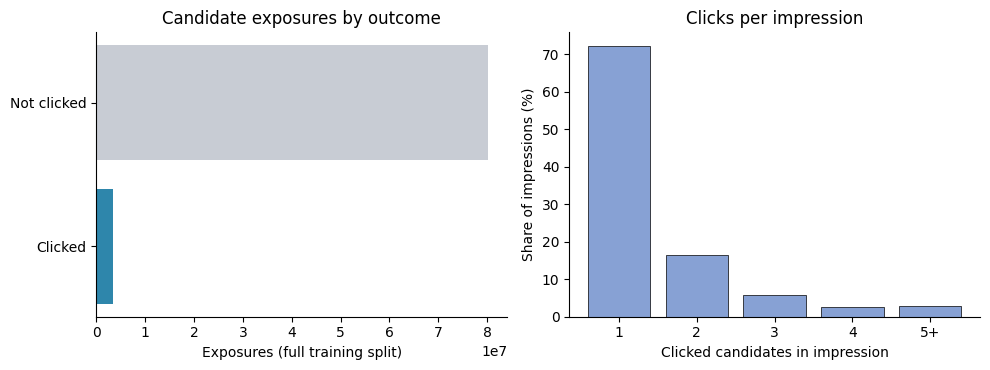

In [12]:
exp_tot, clk_tot = int(art["exposures"].sum()), int(art["clicks"].sum())
print(f"Training split: {exp_tot:,} exposures, {clk_tot:,} clicks ({100 * clk_tot / exp_tot:.2f}%), "
      f"{(exp_tot - clk_tot) / clk_tot:.1f} unclicked per click")
R["train_exposures"], R["train_clicks"] = exp_tot, clk_tot

cpi = (tr["clicks"].clip(upper=5).value_counts(normalize=True).sort_index() * 100).round(1)
cpi.index = [str(i) if i < 5 else "5+" for i in cpi.index]
display(save(cpi.to_frame("share of impressions %"), "clicks_per_impression"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].barh(["Clicked", "Not clicked"], [clk_tot, exp_tot - clk_tot], color=["#2e86ab", "#c8ccd4"])
axes[0].set(title="Candidate exposures by outcome", xlabel="Exposures (full training split)")
axes[1].bar(cpi.index, cpi.values, color="#87a1d4", edgecolor="black", linewidth=.5)
axes[1].set(title="Clicks per impression", xlabel="Clicked candidates in impression", ylabel="Share of impressions (%)")
savefig("fig_funnel_clicks_per_impression")

,articles,share_of_all_%
status,,
Never shown as a candidate (history only),74481,73.4
Shown and clicked,17304,17.0
"Shown, never clicked",9742,9.6


Of the 27,046 articles shown as candidates, 64.0% received at least one click and 36.0% none.
Not in the candidate pool: 74,481 of 101,527 news rows. These appear only in users' click histories (older articles), so they are not cold-start candidates.
Candidate articles missing from news.tsv: 0


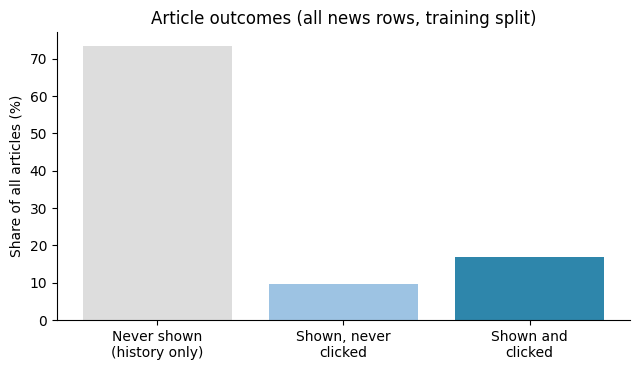

In [13]:
tn = news["Train"]
st = tn[["news_id", "category"]].merge(art[["exposures", "clicks"]], left_on="news_id", right_index=True, how="left")
st[["exposures", "clicks"]] = st[["exposures", "clicks"]].fillna(0)
st["status"] = np.select([st["exposures"] == 0, st["clicks"] == 0],
                         ["Never shown as a candidate (history only)", "Shown, never clicked"], "Shown and clicked")
outcome = st["status"].value_counts().to_frame("articles")
outcome["share_of_all_%"] = (100 * outcome["articles"] / len(st)).round(1)
display(save(outcome, "article_outcomes"))

shown = int((st["exposures"] > 0).sum())
clicked_art = int((st["clicks"] > 0).sum())
print(f"Of the {shown:,} articles shown as candidates, {100 * clicked_art / shown:.1f}% received at least one click "
      f"and {100 * (1 - clicked_art / shown):.1f}% none.")
print(f"Not in the candidate pool: {len(st) - shown:,} of {len(st):,} news rows. These appear only in users' click "
      f"histories (older articles), so they are not cold-start candidates.")
print("Candidate articles missing from news.tsv:", int((~art.index.isin(tn["news_id"])).sum()))
R.update(shown=shown, clicked_art=clicked_art, outcome=outcome)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(["Never shown\n(history only)", "Shown, never\nclicked", "Shown and\nclicked"],
       outcome.reindex(["Never shown as a candidate (history only)", "Shown, never clicked", "Shown and clicked"])["share_of_all_%"],
       color=["#dddddd", "#9dc3e3", "#2e86ab"])
ax.set(title="Article outcomes (all news rows, training split)", ylabel="Share of all articles (%)")
savefig("fig_article_outcomes")

### 3.4 Sparsity and temporal patterns
Item side: how concentrated exposures are among shown articles. User side: history length, impressions per user and gaps between visits. Time: articles per day, article lifespans, weekday and hour effects.

,value
shown_articles,27046.00
top_1%_articles,270.00
top_1%_share_of_exposures_%,38.49
top_10%_articles,2705.00
top_10%_share_%,94.70
bottom_90%_share_%,5.30
median_exposures,50.00


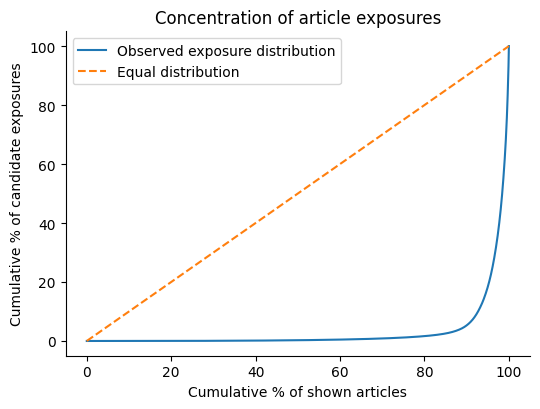

In [14]:
e = np.sort(art["exposures"].to_numpy())
cum, x = np.cumsum(e) / e.sum(), np.arange(1, len(e) + 1) / len(e)
n1, n10 = max(1, round(.01 * len(e))), max(1, round(.10 * len(e)))
top1, top10 = 100 * e[-n1:].sum() / e.sum(), 100 * e[-n10:].sum() / e.sum()
conc = pd.Series({"shown_articles": len(e), "top_1%_articles": n1, "top_1%_share_of_exposures_%": round(top1, 2),
                  "top_10%_articles": n10, "top_10%_share_%": round(top10, 2),
                  "bottom_90%_share_%": round(100 - top10, 2), "median_exposures": np.median(e)})
display(save(conc.to_frame("value"), "exposure_concentration"))
R["conc"] = conc

fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.plot(100 * x, 100 * cum, label="Observed exposure distribution")
ax.plot([0, 100], [0, 100], "--", label="Equal distribution")
ax.set(title="Concentration of article exposures", xlabel="Cumulative % of shown articles",
       ylabel="Cumulative % of candidate exposures")
ax.legend()
savefig("fig_exposure_concentration")

,"history length (user, first session)",sessions per user (training window)
count,711222.00,711222.00
mean,18.77,3.14
std,24.33,2.99
min,0.00,1.00
25%,5.00,1.00
50%,11.00,2.00
75%,22.00,4.00
max,801.00,106.00


Users with no recorded history: 1.81%  |  sessions without history: 2.06%  |  users with a single session: 32.7%
Note: the interim report may define user history length differently (first / last / any session); align the definition before quoting.
Gap between consecutive visits: median 12.8h, mean 18.3h, 15.6% under 1 hour


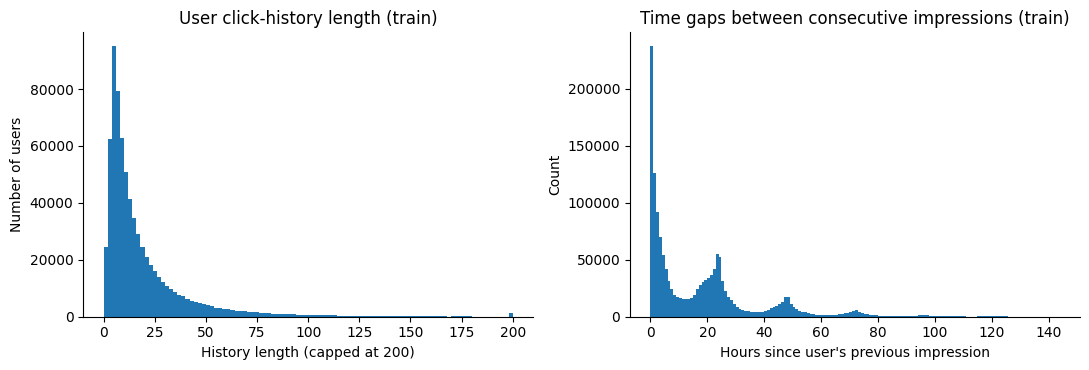

In [15]:
first_sess = tr.sort_values("time").drop_duplicates("user_id")
hist_user = first_sess["hist_len"]                    # history length at each user's first training session
per_user = tr.groupby("user_id").size()               # sessions per user in the 6-day window
user_stats = pd.DataFrame({
    "history length (user, first session)": hist_user.describe().round(2),
    "sessions per user (training window)": per_user.describe().round(2)})
display(save(user_stats, "user_side_stats"))
print(f"Users with no recorded history: {100 * (hist_user == 0).mean():.2f}%  |  "
      f"sessions without history: {100 * (tr['hist_len'] == 0).mean():.2f}%  |  "
      f"users with a single session: {100 * (per_user == 1).mean():.1f}%")
print("Note: the interim report may define user history length differently (first / last / any session); align the definition before quoting.")

g = tr.sort_values(["user_id", "time"])
gap_h = (g.groupby("user_id")["time"].diff().dt.total_seconds() / 3600).dropna()
print(f"Gap between consecutive visits: median {gap_h.median():.1f}h, mean {gap_h.mean():.1f}h, "
      f"{100 * (gap_h < 1).mean():.1f}% under 1 hour")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(hist_user.clip(upper=200), bins=100, color="#2077b4")
axes[0].set(title="User click-history length (train)", xlabel="History length (capped at 200)", ylabel="Number of users")
axes[1].hist(gap_h[gap_h <= 144], bins=144, color="#2077b4")
axes[1].set(title="Time gaps between consecutive impressions (train)", xlabel="Hours since user's previous impression",
            ylabel="Count")
savefig("fig_user_history_and_gaps")
R["user_stats"] = user_stats

,sessions,displays,clicks,ctr_%,weekday,unique_articles_shown,new_articles_first_seen
time,,,,,,,
2019-11-09,192552,7544547,290054,3.84,Sat,6988,6988
2019-11-10,212343,7496213,311416,4.15,Sun,7421,3111
2019-11-11,464467,16583216,683491,4.12,Mon,9640,4544
2019-11-12,478375,16744834,734806,4.39,Tue,9220,4205
2019-11-13,453494,17738458,692845,3.91,Wed,9952,4443
2019-11-14,431517,17400106,671044,3.86,Thu,9107,3755


CTR weekdays 4.06%, weekends 4.00%
Note: the first day has no earlier impressions, so every article looks 'new' on 9 Nov.
Lifespan inside the window (lower bound, cut off at 14 Nov): median 13.2h, mean 26.5h, a quarter under 4.1h


,ctr_%
time,
0,4.198
1,4.046
2,4.062
3,3.993
4,3.872
5,3.983
6,4.037
7,4.276
8,4.201


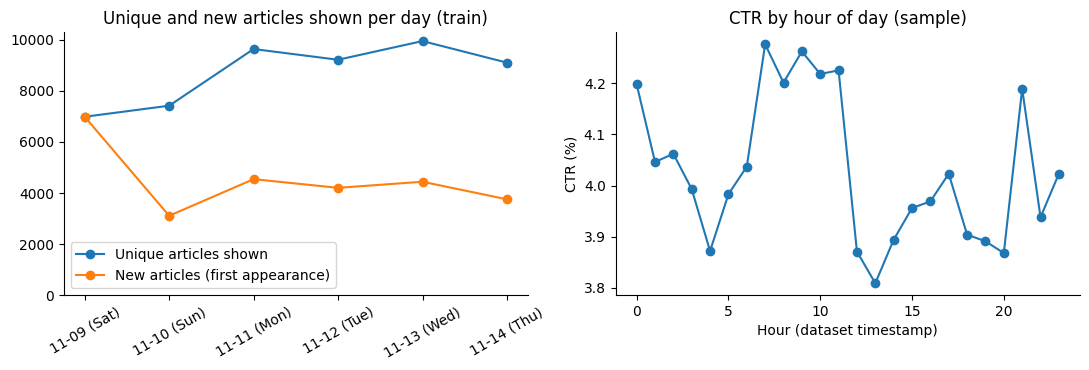

In [16]:
tr_day = tr["time"].dt.strftime("%Y-%m-%d")
daily = tr.groupby(tr_day).agg(sessions=("slate_len", "size"), displays=("slate_len", "sum"), clicks=("clicks", "sum"))
daily["ctr_%"] = (100 * daily["clicks"] / daily["displays"]).round(2)
daily["weekday"] = pd.to_datetime(daily.index).strftime("%a")
daily["unique_articles_shown"] = day_art.groupby("day")["news_id"].nunique()
daily["new_articles_first_seen"] = art["first"].dt.strftime("%Y-%m-%d").value_counts()
display(save(daily, "daily_summary"))

weekend = daily["weekday"].isin(["Sat", "Sun"])
print(f"CTR weekdays {100 * daily.loc[~weekend, 'clicks'].sum() / daily.loc[~weekend, 'displays'].sum():.2f}%, "
      f"weekends {100 * daily.loc[weekend, 'clicks'].sum() / daily.loc[weekend, 'displays'].sum():.2f}%")
print("Note: the first day has no earlier impressions, so every article looks 'new' on 9 Nov.")

life_h = ((art["last"] - art["first"]).dt.total_seconds() / 3600)
print(f"Lifespan inside the window (lower bound, cut off at 14 Nov): median {life_h.median():.1f}h, "
      f"mean {life_h.mean():.1f}h, a quarter under {life_h.quantile(.25):.1f}h")

hour_ctr = (cand.groupby(cand["time"].dt.hour)["label"].mean() * 100).round(3)
display(save(hour_ctr.to_frame("ctr_%"), "ctr_by_hour"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
lab = daily.index.str[5:] + " (" + daily["weekday"] + ")"
axes[0].plot(lab, daily["unique_articles_shown"], "o-", label="Unique articles shown")
axes[0].plot(lab, daily["new_articles_first_seen"], "o-", label="New articles (first appearance)")
axes[0].set(title="Unique and new articles shown per day (train)", ylim=(0, None))
axes[0].legend(); axes[0].tick_params(axis="x", rotation=30)
axes[1].plot(hour_ctr.index, hour_ctr.values, "o-")
axes[1].set(title="CTR by hour of day (sample)", xlabel="Hour (dataset timestamp)", ylabel="CTR (%)")
savefig("fig_daily_and_hourly")
R["daily"] = daily
del cand

## 4. Cold-start exposure and cold-threshold sensitivity
The cold flag used for evaluation is "fewer than `COLD_THRESHOLD` impressions in the training data the model could see", with the counts **frozen at training time** (here: 9-14 Nov, i.e. the whole MIND train folder, which is what a Test-day model sees). The dev split (15 Nov) is then tabulated for a range of thresholds: share of cold displays, cold clicks and cold / warm / mixed impression segments.

Two versions are shown. `train only` (frozen counts) is the definition used in the project and matches the interim report's "never shown in training" wording. `time ordered` additionally counts 15 Nov's own earlier impressions as the day is replayed; it is shown for comparison only, because by the end of the day almost no article is still cold, which leaves too few cold-only impressions to evaluate.

In [17]:
dev = explode_impressions(beh["Dev"], keep_cols=("impression_id", "time"))
dev = dev.sort_values("time", kind="stable").reset_index(drop=True)
dev["prior_train"] = dev["news_id"].map(art["exposures"]).fillna(0).astype("int64")
dev["prior_ordered"] = dev["prior_train"] + dev.groupby("news_id").cumcount()     # + earlier 15 Nov impressions
print(f"Dev: {len(dev):,} candidate rows, {dev['news_id'].nunique():,} distinct articles")


def cold_table(d, col, thresholds=(1, 2, 5, 10, 20, 50, 100)):
    clicked = (d["label"] == 1).to_numpy()
    n_click, ctr_all = clicked.sum(), clicked.mean()
    first = d.drop_duplicates("news_id")[col].to_numpy()            # prior count at each article's first dev display
    imp = d["impression_id"].to_numpy()[clicked]
    rows = []
    for T in thresholds:
        cold = (d[col] < T).to_numpy()
        seg = pd.DataFrame({"i": imp, "c": cold[clicked]}).groupby("i")["c"].agg(["min", "max"])
        rows.append({"threshold": T,
                     "cold_articles_%": 100 * (first < T).mean(),
                     "cold_displays_%": 100 * cold.mean(),
                     "cold_clicks_%": 100 * (cold & clicked).sum() / n_click,
                     "cold_CTR_vs_average": ((cold & clicked).sum() / cold.sum()) / ctr_all if cold.sum() else np.nan,
                     "impressions_cold_%": 100 * seg["min"].astype(bool).mean(),
                     "impressions_warm_%": 100 * (~seg["max"].astype(bool)).mean()})
    out = pd.DataFrame(rows).set_index("threshold")
    out["impressions_mixed_%"] = 100 - out["impressions_cold_%"] - out["impressions_warm_%"]
    return out.round(2)


cold_ordered = save(cold_table(dev, "prior_ordered"), "cold_sensitivity_time_ordered")
cold_train = save(cold_table(dev, "prior_train"), "cold_sensitivity_train_only")
print("Time-ordered prior impressions (comparison only, NOT the project definition: cold shrinks during the day):")
display(cold_ordered)
print("Train-only prior impressions = counts frozen at training time (THE definition used for the cold flag; matches the report's 'never shown in training' wording):")
display(cold_train)
R["cold_ordered"], R["cold_train"] = cold_ordered, cold_train

Dev: 14,085,557 candidate rows, 6,997 distinct articles
Time-ordered prior impressions (comparison only, NOT the project definition: cold shrinks during the day):


,cold_articles_%,cold_displays_%,cold_clicks_%,cold_CTR_vs_average,impressions_cold_%,impressions_warm_%,impressions_mixed_%
threshold,,,,,,,
1,32.34,0.02,0.02,1.27,0.01,99.97,0.02
2,36.04,0.03,0.04,1.29,0.02,99.94,0.05
5,40.36,0.08,0.10,1.23,0.04,99.85,0.10
10,43.30,0.16,0.19,1.21,0.09,99.72,0.19
20,47.45,0.30,0.36,1.20,0.20,99.47,0.34
50,53.71,0.67,0.77,1.15,0.43,98.88,0.69
100,58.74,1.16,1.28,1.11,0.71,98.17,1.12


Train-only prior impressions = counts frozen at training time (THE definition used for the cold flag; matches the report's 'never shown in training' wording):


,cold_articles_%,cold_displays_%,cold_clicks_%,cold_CTR_vs_average,impressions_cold_%,impressions_warm_%,impressions_mixed_%
threshold,,,,,,,
1,32.34,5.38,8.75,1.63,7.35,87.63,5.02
2,36.04,7.73,12.22,1.58,10.55,83.37,6.09
5,40.36,11.84,17.04,1.44,15.23,77.24,7.54
10,43.30,17.93,23.46,1.31,20.51,69.81,9.69
20,47.45,28.29,32.87,1.16,28.33,60.20,11.46
50,53.71,43.53,49.36,1.13,43.49,42.24,14.27
100,58.74,53.63,56.96,1.06,50.76,35.41,13.83


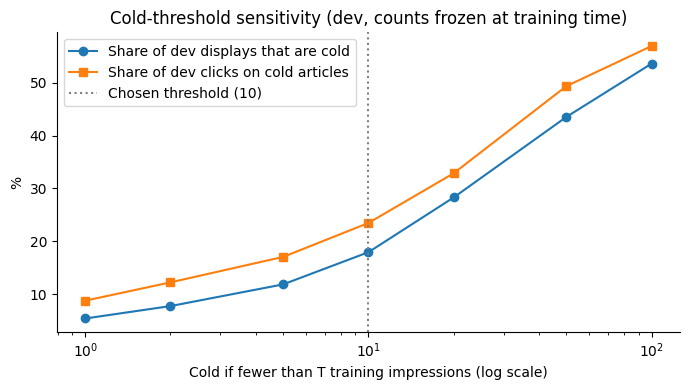

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cold_train.index, cold_train["cold_displays_%"], "o-", label="Share of dev displays that are cold")
ax.plot(cold_train.index, cold_train["cold_clicks_%"], "s-", label="Share of dev clicks on cold articles")
ax.axvline(config.COLD_THRESHOLD, color="grey", ls=":", label=f"Chosen threshold ({config.COLD_THRESHOLD})")
ax.set(xscale="log", title="Cold-threshold sensitivity (dev, counts frozen at training time)",
       xlabel="Cold if fewer than T training impressions (log scale)", ylabel="%")
ax.legend()
savefig("fig_cold_threshold_sensitivity")
del dev

## 5. Feature dictionary and descriptive statistics (report Section 4)
### 5.1 Numeric features
`clicked` uses every training candidate; word counts use the training `news.tsv`; slate and history length are per session (300k sample).

In [19]:
tn = news["Train"]
title_wc = tn["title"].str.split().str.len()
abs_wc = tn["abstract"].str.split().str.len().replace(0, np.nan)        # blank abstract = missing
p = clk_tot / exp_tot
numeric = pd.DataFrame([
    {"feature": "clicked (target label)", "n": exp_tot, "missing": 0, "min": 0, "median": 0,
     "mean": round(p, 4), "std": round((p * (1 - p)) ** .5, 4), "max": 1},
    describe_num(title_wc, "title_word_count"),
    describe_num(abs_wc, "abstract_word_count"),
    describe_num(samp["slate_len"], "impression_slate_length"),
    describe_num(samp["hist_len"], "user_history_length")]).set_index("feature")
display(save(numeric, "numeric_features"))
R.update(title_wc=title_wc, abs_wc=abs_wc)

,n,missing,min,median,mean,std,max
feature,,,,,,,
clicked (target label),83507374,0,0.0,0.0,0.0405,0.1972,1.0
title_word_count,101527,0,1.0,10.0,10.6635,3.2385,48.0
abstract_word_count,96112,5415,1.0,27.0,38.2832,26.1930,474.0
impression_slate_length,300000,0,2.0,25.0,37.3576,38.6243,299.0
user_history_length,300000,0,0.0,19.0,32.9078,40.7321,801.0


### 5.2 Categorical features
Category counts are for all training news rows (including history-only articles). The exposure columns show what users were actually shown, which is not the same mix.

,articles,exposures,clicks,article_share_%,exposure_share_%,ctr_%
category,,,,,,
sports,32020,8439316.0,396445.0,31.5,10.1,4.70
news,30478,22779114.0,996645.0,30.0,27.3,4.38
finance,5916,8066103.0,292574.0,5.8,9.7,3.63
travel,4955,4512849.0,118724.0,4.9,5.4,2.63
lifestyle,4570,9351261.0,382282.0,4.5,11.2,4.09
video,4569,1355971.0,62484.0,4.5,1.6,4.61
foodanddrink,4418,5276950.0,158336.0,4.4,6.3,3.00
weather,4255,1279127.0,65545.0,4.2,1.5,5.12
autos,3071,3844996.0,105667.0,3.0,4.6,2.75


,distinct,missing_or_blank,top3
feature,,,
category,18,0,"sports (32,020); news (30,478); finance (5,916)"
subcategory,285,0,"newsus (14,467); football_nfl (11,813); newspo..."


Subcategories mapped to exactly 1 category: 269; to several: 16 (animals, causes, holidays, humor, lifestyle, ...)


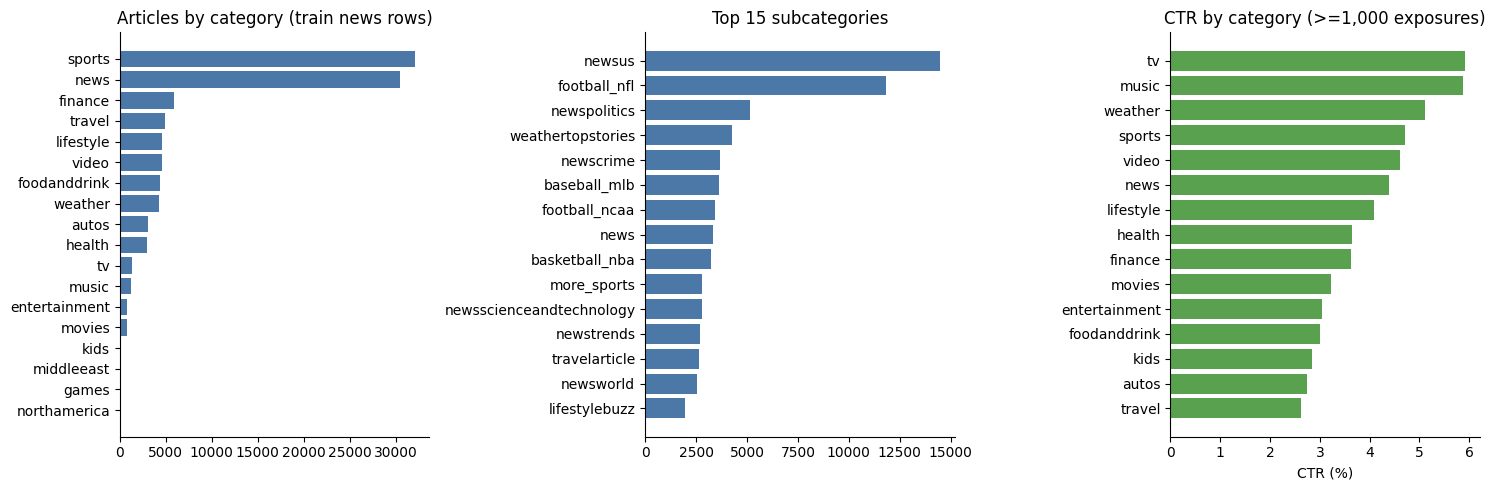

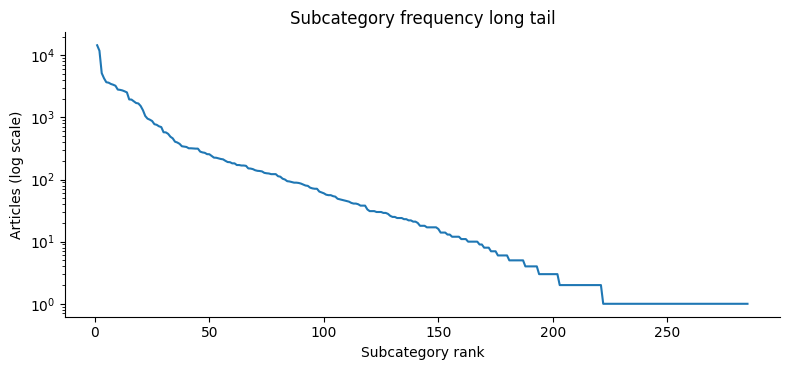

In [20]:
cat = st.groupby("category").agg(articles=("news_id", "size"), exposures=("exposures", "sum"), clicks=("clicks", "sum"))
cat["article_share_%"] = (100 * cat["articles"] / cat["articles"].sum()).round(1)
cat["exposure_share_%"] = (100 * cat["exposures"] / cat["exposures"].sum()).round(1)
cat["ctr_%"] = (100 * cat["clicks"] / cat["exposures"].where(cat["exposures"] > 0)).round(2)
cat = cat.sort_values("articles", ascending=False)
display(save(cat, "category_table"))

sub = tn["subcategory"].value_counts()
sub_cats = tn.groupby("subcategory")["category"].nunique()
cat_summary = pd.DataFrame([
    {"feature": "category", "distinct": tn["category"].nunique(), "missing_or_blank": int((tn["category"].str.strip() == "").sum()),
     "top3": "; ".join(f"{k} ({v:,})" for k, v in tn["category"].value_counts().head(3).items())},
    {"feature": "subcategory", "distinct": tn["subcategory"].nunique(), "missing_or_blank": int((tn["subcategory"].str.strip() == "").sum()),
     "top3": "; ".join(f"{k} ({v:,})" for k, v in sub.head(3).items())}]).set_index("feature")
display(save(cat_summary, "categorical_summary"))
print(f"Subcategories mapped to exactly 1 category: {(sub_cats == 1).sum()}; to several: {(sub_cats > 1).sum()} "
      f"({', '.join(sub_cats[sub_cats > 1].index[:5])}, ...)")
R.update(cat_summary=cat_summary, sub_cats=sub_cats)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
c = cat["articles"].sort_values()
axes[0].barh(c.index, c.values, color="#4c78a8"); axes[0].set(title="Articles by category (train news rows)")
s15 = sub.head(15)[::-1]
axes[1].barh(s15.index, s15.values, color="#4c78a8"); axes[1].set(title="Top 15 subcategories")
cc = cat[cat["exposures"] >= 1000].sort_values("ctr_%")
axes[2].barh(cc.index, cc["ctr_%"], color="#59a14f"); axes[2].set(title="CTR by category (>=1,000 exposures)", xlabel="CTR (%)")
savefig("fig_categories")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.semilogy(np.arange(1, len(sub) + 1), sub.values)
ax.set(title="Subcategory frequency long tail", xlabel="Subcategory rank", ylabel="Articles (log scale)")
savefig("fig_subcategory_long_tail")

### 5.3 Text, corpus and media
Word counts, vocabulary, missing abstracts, whether the two-peaked abstract length is driven by category, entity counts and URL checks.

Vocabulary (lowercased alphanumeric words): titles 40,987, abstracts 69,065
Blank abstracts: 5,415 (5.33%)


,articles,median,share_over_50_words
category,,,
sports,29626,25.0,31.8
news,29365,36.0,42.2
finance,5778,24.0,24.3
travel,4605,30.0,41.5
video,4563,25.0,9.1
foodanddrink,4319,22.0,25.6
lifestyle,4256,24.0,28.1
weather,3820,37.0,42.8
health,2815,23.0,18.5


Abstracts over 50 words overall: 33.3%  (the second peak of the histogram)


,value
mean_entities_title,1.19
mean_entities_abstract,1.97
share_no_title_entity_%,25.66
share_no_abstract_entity_%,25.10
share_abstract_entities>=title_entities_%,79.60


,value
total_articles,101527
blank_url,0
unique_non_blank_urls,101527
rows_sharing_a_url,0


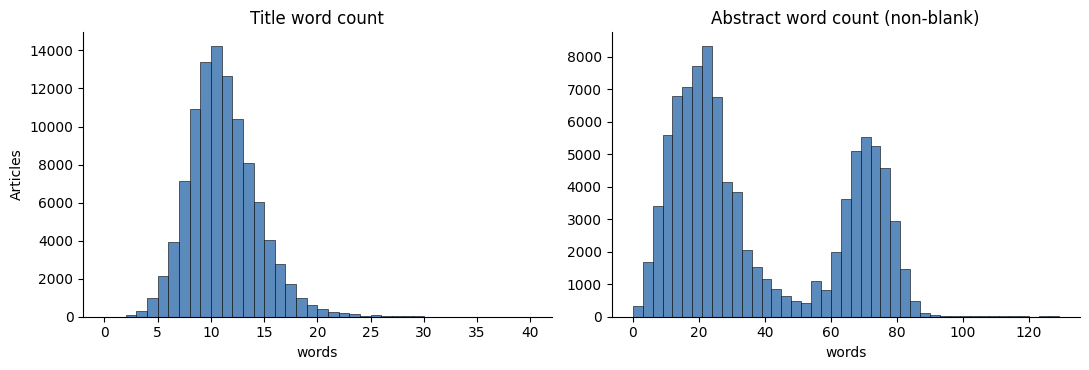

In [21]:
def vocab_size(s):
    v = set()
    for t in s:
        v.update(re.findall(r"[a-z0-9]+", t.lower()))
    return len(v)


R["vocab_title"], R["vocab_abstract"] = vocab_size(tn["title"]), vocab_size(tn["abstract"])
print(f"Vocabulary (lowercased alphanumeric words): titles {R['vocab_title']:,}, abstracts {R['vocab_abstract']:,}")
print(f"Blank abstracts: {int(abs_wc.isna().sum()):,} ({100 * abs_wc.isna().mean():.2f}%)")

by_cat = pd.DataFrame({"abs_wc": abs_wc, "category": tn["category"]}).groupby("category")["abs_wc"].agg(
    articles="count", median="median", share_over_50_words=lambda x: round(100 * (x > 50).mean(), 1))
display(save(by_cat.sort_values("articles", ascending=False), "abstract_length_by_category"))
print(f"Abstracts over 50 words overall: {100 * (abs_wc > 50).mean():.1f}%  (the second peak of the histogram)")

te = tn["title_entities"].str.count('"WikidataId"')
ae = tn["abstract_entities"].str.count('"WikidataId"')
ent = pd.Series({"mean_entities_title": te.mean(), "mean_entities_abstract": ae.mean(),
                 "share_no_title_entity_%": 100 * (te == 0).mean(), "share_no_abstract_entity_%": 100 * (ae == 0).mean(),
                 "share_abstract_entities>=title_entities_%": 100 * (ae >= te).mean()}).round(2)
display(save(ent.to_frame("value"), "entity_counts"))

u = tn["url"]
blank = u.str.strip() == ""
url_tbl = pd.Series({"total_articles": len(u), "blank_url": int(blank.sum()),
                     "unique_non_blank_urls": int(u[~blank].nunique()),
                     "rows_sharing_a_url": int(u[~blank].duplicated(keep=False).sum())})
display(save(url_tbl.to_frame("value"), "url_check"))
R["url_tbl"] = url_tbl

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(title_wc.dropna(), bins=range(0, 41), color="#5b8bbd", edgecolor="black", linewidth=.4)
axes[0].set(title="Title word count", xlabel="words", ylabel="Articles")
axes[1].hist(abs_wc.dropna(), bins=range(0, 130, 3), color="#5b8bbd", edgecolor="black", linewidth=.4)
axes[1].set(title="Abstract word count (non-blank)", xlabel="words")
savefig("fig_text_lengths")

## 6. Check against the interim report
Every number quoted in the interim report that this notebook can reproduce. Differences in the 300k-sample rows are expected (different random draw); everything else should match exactly (apart from rounding and the vocabulary tokenizer). The all-splits totals need the optional test folder and are skipped without it.

In [22]:
checks = []
def fmt(v):
    if pd.isna(v):
        return "n/a"
    return f"{int(round(v)):,}" if abs(v - round(v)) < 1e-9 else f"{v:,.2f}"


def chk(name, got, want, tol=0):
    ok = (abs(got - want) <= tol) if pd.notna(got) else False
    d = got - want if pd.notna(got) else np.nan
    checks.append({"item": name, "this notebook": fmt(got), "interim report": fmt(want),
                   "difference": fmt(d), "difference_%": round(100 * d / want, 2) if pd.notna(d) and want else np.nan,
                   "match": "OK" if ok else "CHECK"})

cv = R["coverage"]
for s, v in {"Train": (2232748, 711222, 101527, 83507374, 3383656, 46065), "Dev": (376471, 255990, 72023, 14085557, 574845, 11270),
             "Test": (2370727, 702005, 120961, 93115001, np.nan, 29108)}.items():
    if s not in cv.index:
        continue                                  # optional test folder not present
    for col, want in zip(["sessions", "unique_users", "unique_articles", "candidate_displays", "clicked", "sessions_without_history"], v):
        if pd.notna(want):
            chk(f"{s} {col}", cv.loc[s, col], want)
for k, want in ({"sessions": 4979946, "unique_users": 876956, "unique_articles": 130379, "candidate_displays": 190707932}.items() if HAS_TEST else []):
    chk(f"All splits {k}", R["overall"][k], want)
chk("Shown as candidates (train)", R["shown"], 27046)
chk("Shown and clicked (train)", R["clicked_art"], 17304)
chk("Shown, never clicked (train)", R["shown"] - R["clicked_art"], 9742)
chk("Never shown / history only", len(tn) - R["shown"], 74481)
chk("Top 1% share of exposures (%)", R["conc"]["top_1%_share_of_exposures_%"], 38.57, 0.1)
chk("Top 10% share of exposures (%)", R["conc"]["top_10%_share_%"], 94.70, 0.1)
chk("Title word count mean", R["title_wc"].mean(), 10.67, 0.005)
chk("Blank abstracts", int(R["abs_wc"].isna().sum()), 5415)
chk("Vocabulary titles", R["vocab_title"], 50633)
chk("Vocabulary abstracts", R["vocab_abstract"], 76863)
chk("Categories", R["cat_summary"].loc["category", "distinct"], 18)
chk("Subcategories", R["cat_summary"].loc["subcategory", "distinct"], 285)
chk("Subcategories with one category", int((R["sub_cats"] == 1).sum()), 269)
chk("Subcategories with several categories", int((R["sub_cats"] > 1).sum()), 16)
ct = R["cold_train"]
chk("Dev cold displays, never in train (%)", ct.loc[1, "cold_displays_%"], 5.4, 0.05)
chk("Dev cold clicks, never in train (%)", ct.loc[1, "cold_clicks_%"], 8.8, 0.05)
chk("Dev cold displays, <10 train impressions (%)", ct.loc[10, "cold_displays_%"], 17.9, 0.05)
chk("Dev cold clicks, <10 train impressions (%)", ct.loc[10, "cold_clicks_%"], 23.5, 0.05)
check_df = save(pd.DataFrame(checks).set_index("item"), "report_number_check")
print(f"{(check_df['match'] == 'OK').sum()} of {len(check_df)} numbers match the interim report")
differences = save(check_df[check_df["match"] == "CHECK"], "differences_vs_interim")
print("Numbers that differ from the interim report (candidates for the final report's Section 1):")
display(differences)
with pd.option_context("display.max_rows", None):
    display(check_df)

35 of 39 numbers match the interim report
Numbers that differ from the interim report (candidates for the final report's Section 1):


,this notebook,interim report,difference,difference_%,match
item,,,,,
Title word count mean,10.66,10.67,-0.01,-0.06,CHECK
Vocabulary titles,"40,987","50,633","-9,646",-19.05,CHECK
Vocabulary abstracts,"69,065","76,863","-7,798",-10.15,CHECK
"Dev cold clicks, never in train (%)",8.75,8.80,-0.05,-0.57,CHECK


,this notebook,interim report,difference,difference_%,match
item,,,,,
Train sessions,"2,232,748","2,232,748",0,0.00,OK
Train unique_users,"711,222","711,222",0,0.00,OK
Train unique_articles,"101,527","101,527",0,0.00,OK
Train candidate_displays,"83,507,374","83,507,374",0,0.00,OK
Train clicked,"3,383,656","3,383,656",0,0.00,OK
Train sessions_without_history,"46,065","46,065",0,0.00,OK
Dev sessions,"376,471","376,471",0,0.00,OK
Dev unique_users,"255,990","255,990",0,0.00,OK
Dev unique_articles,"72,023","72,023",0,0.00,OK


## Notes for the report

**Overall:** 35 of 39 interim numbers reproduce on the full data. The rest are listed below.

| Item | Interim report | Now (full data, Fit/Tune/Test) | Why it matters |
|---|---|---|---|
| Cold-flag definition | Section 1.2 says counts accumulate chronologically through 15 Nov, but its Section 3.4 figures (17.9% of displays, 23.5% of clicks) use training-only counts | Counts frozen at training time (Fit for Tune, Fit+Tune for Test). At threshold 10, a running count leaves only 0.16% of Test displays cold and 0.09% of impressions cold-only (0.19% mixed). Frozen counts give 17.93% of displays and 20.51% / 9.69% / 69.81% cold-only / mixed / warm impressions | A running count leaves too few cold impressions to evaluate. The frozen count matches what a model knows at training time and the interim's own numbers. The 9 Nov exclusion no longer matters for Tune/Test reporting |
| Split table (new) | Plan only, no numbers | Fit: 1,801,231 sessions, CTR 4.10%, 1.92% without history. Tune: 431,517, 3.86%, 2.64%. Test: 376,471, 4.08%, 2.99%. Median slate 24 / 26 / 23 | Tune is not identical to Test, so choose lambda and threshold on Tune and use Test once |
| Cold-threshold sensitivity (new) | Only mentions it "can be varied" | Threshold 5: 11.84% of displays, 17.04% of clicks. Threshold 10: 17.93% / 23.46%. Threshold 20: 28.29% / 32.87% | Shows the conclusions do not hinge on 10 |
| Vocabulary size | Titles 50,633; abstracts 76,863 | Titles 40,987; abstracts 69,065 | Tokenizer difference (here: lowercase alphanumeric words). State the definition if quoted |
| Minor rounding | Top-1% exposure share 38.57; title length 10.67; dev cold clicks never in train 8.80 | 38.49; 10.66; 8.75 | No action; counting and rounding conventions |

**Findings for Sections 3 and 4**
1. Cold articles are a bigger problem than cold users. At threshold 10, cold articles are 43.30% of Test articles, 17.93% of displays and 23.46% of clicks. Only 2.99% of Test impressions have no history.
2. Cold articles are clicked more than their display share suggests: CTR is 1.31x the average at threshold 10 and 1.63x for articles never seen in training, fading to 1.06x at threshold 100. This is an observation, not a causal claim.
3. Exposure is concentrated: the top 1% of shown articles (270) take 38.49% of training exposures and the top 10% take 94.70%. The median shown article has 50 exposures. A further 73.4% of news rows never appear as candidates. Popularity-based models will favour the head.
4. 27.09% of slates in the 300k-session training sample have 10 or fewer candidates, so re-ranking cannot change which articles reach the top 10 for them. Report exposure and diversity by slate length (step 6 already does this).